# 04 — Imagens como dados: cutouts, RGB e dataset visual

Workshop SAB — AI-Scope / ADSS

**Pergunta científica:** como transformar uma lista de coordenadas em um conjunto de imagens reproduzível para inspeção ou deep learning?

Aqui a unidade de análise deixa de ser uma linha de catálogo. Usaremos as coleções de arquivos do ADSS para produzir cutouts sob demanda e composições RGB, sem manter cópias locais de campos completos.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import adss

BASE_URL = "https://ai-scope.cbpf.br/"

cl = adss.ADSSClient(base_url=BASE_URL)

In [3]:
collections = pd.DataFrame(cl.get_collections())
collections[[c for c in ["id","name","description"] if c in collections.columns]]

,id,name,description
0,4,splus dr1-dr4,
1,3,splus idr6,splus idr6 collection


In [4]:
# Escolha uma coleção que possua WCS e ajuste estas coordenadas a uma região coberta.
COLLECTION_ID = int(collections.iloc[0].id)
RA, DEC = 0.1, 0.1

files = cl.list_files(COLLECTION_ID)
pd.DataFrame(files).head()

,filename,full_path,file_type,ra_center,dec_center,width,height,pixel_scale,hdus,data_hdu,object_name,filter,instrument,telescope,date_obs,file_size,id,collection_id,created_at,updated_at
0,MC0113_U_swpweight.fz,/dados/splus/MC0113/MC0113_U_swpweight.fz,fz,4.736574,-73.461596,11000.0,11000.0,0.55,2.0,1.0,MC0113,U,T80Cam,T80,None,59477760,154955,4,2026-04-29T12:26:10.012991,2026-04-29T12:26:10.012991
1,SPLUS-s17s23_U_swp.fz,/dados/splus/SPLUS-s17s23/SPLUS-s17s23_U_swp.fz,fz,316.451531,-21.580561,11000.0,11000.0,0.55,2.0,1.0,SPLUS-s17s23,U,T80Cam,T80,None,53058240,154988,4,2026-04-29T12:26:11.941936,2026-04-29T12:26:11.941936
2,SPLUS-s17s23_G_swp.fz,/dados/splus/SPLUS-s17s23/SPLUS-s17s23_G_swp.fz,fz,316.451531,-21.580561,11000.0,11000.0,0.55,2.0,1.0,SPLUS-s17s23,G,T80Cam,T80,None,52859520,154996,4,2026-04-29T12:26:12.542531,2026-04-29T12:26:12.542531
3,SPLUS-d232_U_swpweight.fz,/dados/splus/SPLUS-d232/SPLUS-d232_U_swpweight.fz,fz,101.703948,-29.463100,11000.0,11000.0,0.55,2.0,1.0,SPLUS-d232,U,T80Cam,T80,None,52980480,155014,4,2026-04-29T12:26:12.979684,2026-04-29T12:26:12.979684
4,fz_sorted_ima_swp.list,/dados/splus/HYDRA-0067/fz_sorted_ima_swp.list,list,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,4096,155023,4,2026-04-29T12:26:13.447576,2026-04-29T12:26:13.447576


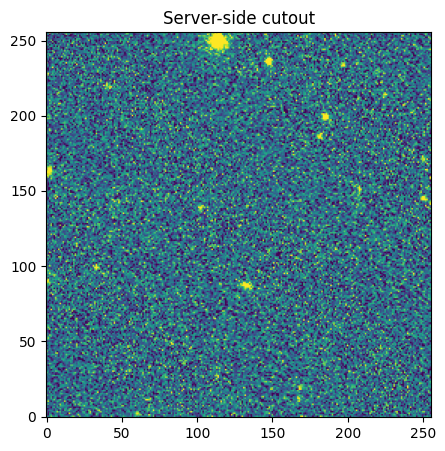

In [13]:
from io import BytesIO
from astropy.io import fits

cutout_bytes = cl.create_stamp_by_coordinates(
    collection_id=COLLECTION_ID,
    ra=RA,
    dec=DEC,
    size=256,
    filter="R",
    size_unit="pixels",
    format="fits",
    pattern="swp.",
)

with fits.open(BytesIO(cutout_bytes)) as hdul:
    image = hdul[0].data if hdul[0].data is not None else hdul[1].data

fig, ax = plt.subplots(figsize=(5,5))
lo, hi = np.nanpercentile(image, [5, 99.5])
ax.imshow(image, origin="lower", vmin=lo, vmax=hi)
ax.set(title="Server-side cutout")
plt.show()

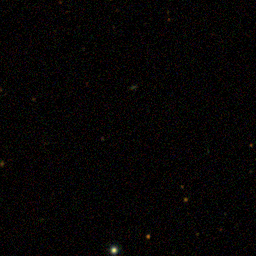

In [14]:
from PIL import Image

rgb_bytes = cl.create_rgb_image_by_coordinates(
    collection_id=COLLECTION_ID,
    ra=RA,
    dec=DEC,
    size=256,
    size_unit="pixels",
    r_filter="I",
    g_filter="R",
    b_filter="G",
)
rgb = Image.open(BytesIO(rgb_bytes))
rgb

### De visualização para ML
O mesmo mecanismo pode receber uma tabela com milhares de coordenadas e gerar amostras homogêneas. Uma atividade útil é definir um *manifest* com `object_id`, coordenadas, filtros, tamanho do stamp e rótulo científico. Isso torna a construção do dataset rastreável e repetível.